# Yield Curve Regimes & Equity Positioning
## Week 7: Today’s regime and the sector call

**Research question:** How have U.S. stock sectors performed in each yield-curve environment since 1976, and **what does today’s environment suggest about which sectors are best positioned?**

Weeks 5 and 6 answered the first half of the question. This week answers the second half:
1. **Find today’s regime.** Download fresh Treasury yields and label the latest finished month with your Week 3 rule.
2. **Gather the evidence for that regime.** Run your Week 5 numbers and all four Week 6 checks for every sector in that regime.
3. **Make the call.** The notebook builds a shortlist; the worksheet walks you through choosing the sector, and then one company to value in Weeks 8–10.

**How to run it:** upload it to [Google Colab](https://colab.research.google.com) (File → Upload notebook), then **Runtime → Run all**. Step 2 downloads two small files from FRED. If FRED blocks Colab (like in Week 1), it shows two download links and an upload button.

### 1. Load your history
**What this does:** reads your Week 1 dataset from GitHub. It holds the yields and sector returns behind every result so far.

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

GITHUB_CSV = "https://raw.githubusercontent.com/caden-smalls-greenwood/yield-curve-regimes/main/monthly_dataset.csv"
LOCAL_CSV  = Path("monthly_dataset.csv")
DATA = Path("data");    DATA.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

def load_dataset():
    if LOCAL_CSV.exists():
        print("Using the monthly_dataset.csv already in this folder.")
        return pd.read_csv(LOCAL_CSV)
    try:
        r = requests.get(GITHUB_CSV, timeout=30)
        r.raise_for_status()
        print("Loaded monthly_dataset.csv from your GitHub repository.")
        return pd.read_csv(io.StringIO(r.text))
    except requests.RequestException as e:
        print(f"Couldn't reach GitHub ({type(e).__name__}). Click 'Choose Files' and pick monthly_dataset.csv.")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Put monthly_dataset.csv in this notebook's folder and run this cell again.")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

raw = load_dataset()
data = raw.set_index(pd.PeriodIndex(raw["month"], freq="M")).drop(columns="month").iloc[:-1]   # drop the partial last month

SECTORS = ["Nondurables", "Durables", "Manufacturing", "Energy", "Chemicals", "Tech",
           "Telecom", "Utilities", "Retail", "Healthcare", "Finance", "Other"]
REGIMES = ["Bull steepener", "Bear steepener", "Bull flattener", "Bear flattener"]
print(f"History: {len(data)} months, {data.index.min()} to {data.index.max()}")

Loaded monthly_dataset.csv from your GitHub repository.
History: 604 months, 1976-06 to 2026-09


### 2. Download fresh Treasury yields from FRED
Your dataset’s yields stop at September 2026. This cell downloads the daily **10-year (DGS10)** and **2-year (DGS2)** yields so the notebook can label the months since then.

**If FRED doesn’t answer Colab** within about 20 seconds, you’ll see **Plan B**: two links and an upload button. Click each link (the file downloads in your own browser), then click **Choose Files** and pick both files from your Downloads folder. Their names don’t matter; the notebook recognizes them by what’s inside.

In [2]:
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
HEADERS  = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/126.0 Safari/537.36"}
TIMEOUT  = (10, 20)                    # seconds to connect, seconds to wait for data
SERIES   = {"DGS10": "10-year Treasury yield, daily (%)", "DGS2": "2-year Treasury yield, daily (%)"}

def parse_fred(text):
    df = pd.read_csv(io.StringIO(text.lstrip("﻿")), na_values=[".", ""])
    sid = str(df.columns[1]).strip()
    df.columns = ["date", sid]
    df["date"] = pd.to_datetime(df["date"])
    return sid, pd.to_numeric(df.set_index("date")[sid], errors="coerce").dropna()

def fred_from_files(files):
    """Find DGS10 and DGS2 among {name: bytes} by their column header, not their file name."""
    found = {}
    for raw_bytes in files.values():
        text = raw_bytes.decode("utf-8", errors="ignore").lstrip("﻿")
        header = [c.strip().strip('"') for c in text.split("\n", 1)[0].split(",")]
        if len(header) == 2 and header[1] in SERIES:
            sid, s = parse_fred(text)
            found[sid] = s
    return found

# 1) Files already uploaded (so re-running is instant)
fred = fred_from_files({p.name: p.read_bytes() for p in Path(".").glob("*.csv") if p.name != LOCAL_CSV.name})
# 2) Ask FRED directly
try:
    for sid in [s for s in SERIES if s not in fred]:
        r = requests.get(FRED_URL.format(sid), headers=HEADERS, timeout=TIMEOUT)
        r.raise_for_status()
        fred[sid] = parse_fred(r.text)[1]
except requests.RequestException as e:
    print(f"FRED didn't answer Colab ({type(e).__name__}). Switching to Plan B.\n")
# 3) Plan B: download in your own browser, then upload
missing = [s for s in SERIES if s not in fred]
if missing:
    links = "".join(f'<li><a href="{FRED_URL.format(s)}" target="_blank">{s}: {SERIES[s]}</a></li>' for s in missing)
    display(HTML(f"<p><b>Plan B: click each link to download the file, then click Choose Files below and pick them.</b></p><ol>{links}</ol>"))
    try:
        from google.colab import files
        fred.update(fred_from_files(files.upload()))
    except ImportError:
        pass
missing = [s for s in SERIES if s not in fred]
if missing:
    raise RuntimeError(f"Still missing {', '.join(missing)}. Download it from the link above, then run this cell again.")

for sid, s in fred.items():
    print(f"{sid:6s} daily data through {s.index.max():%B %d, %Y}")

FRED didn't answer Colab (ReadTimeout). Switching to Plan B.



Saving DGS2.csv to DGS2.csv
Saving DGS10.csv to DGS10.csv


/tmp/ipykernel_491/2713652738.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])
/tmp/ipykernel_491/2713652738.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"])


DGS2   daily data through November 12, 2026
DGS10  daily data through December 31, 2075


### 3. Turn the daily yields into month-end values
Same as Week 1: keep the **last trading day of each month**. A month only counts once it is **over**, so the current month is set aside as an “early read” and never used for the call.

**Check:** for the months your dataset already has, the fresh month-end yields should match it exactly. Same source, same days, same numbers.

In [3]:
def month_end(s):
    return s.groupby(s.index.to_period("M")).last()

fresh = pd.DataFrame({"y10": month_end(fred["DGS10"]), "y2": month_end(fred["DGS2"])}).dropna()
this_month = pd.Timestamp.today().to_period("M")
early = fresh.loc[[this_month]] if this_month in fresh.index else None
fresh = fresh[fresh.index < this_month]                       # only finished months

overlap = fresh.index.intersection(data.index)[-12:]
gap = (fresh.loc[overlap, ["y10", "y2"]] - data.loc[overlap, ["y10", "y2"]]).abs().max().max()
print(f"Check against your dataset (last {len(overlap)} shared months): biggest difference = {gap:.4f} percentage points")

yields = pd.concat([data[["y10", "y2"]], fresh.loc[fresh.index > data.index.max()]])
yields["spread_10y2y"] = yields["y10"] - yields["y2"]
new_months = [str(m) for m in yields.index[yields.index > data.index.max()]]
print(f"New finished months added: {', '.join(new_months) if new_months else 'none yet'}")
print(f"Latest finished month: {yields.index.max()}")

Check against your dataset (last 12 shared months): biggest difference = 0.0000 percentage points
New finished months added: 2026-10
Latest finished month: 2026-10


### 4. Label the latest months with your Week 3 rule
The same rule as always: compare each month-end with the month-end **3 months earlier**.
- 10-year yield fell → **bull**; rose → **bear**.
- 10y–2y spread widened → **steepener**; narrowed → **flattener**.

The table also shows the 6-month window and the “clear moves” check from Week 6, so you can see whether today’s label is solid or borderline.

In [4]:
def label(y, window=3, min_move=0.0):
    c10 = (y["y10"] - y["y10"].shift(window)).round(4)
    cs  = (y["spread_10y2y"] - y["spread_10y2y"].shift(window)).round(4)
    lab = pd.Series([f"{'Bull' if a < 0 else 'Bear'} {'steepener' if b > 0 else 'flattener'}" for a, b in zip(c10, cs)],
                    index=y.index)
    return lab.mask(c10.isna() | cs.isna() | (c10.abs() < min_move) | (cs.abs() < min_move)), c10, cs

lab3, chg_10y, chg_slope = label(yields)
recent = pd.DataFrame({"10y": yields["y10"], "2y": yields["y2"], "10y–2y": yields["spread_10y2y"].round(2),
                       "3-mo change, 10y": chg_10y, "3-mo change, spread": chg_slope, "Regime (3-month)": lab3,
                       "6-month window": label(yields, 6)[0],
                       "Clear moves only": label(yields, 3, 0.10)[0].fillna("unclear")}).tail(8)

CURRENT = lab3.iloc[-1]
streak = int((lab3[::-1] == CURRENT).astype(int).cumprod().sum())
print(f"TODAY'S REGIME: {CURRENT} (latest finished month {lab3.index[-1]}), "
      f"{streak} month{'s' if streak > 1 else ''} in a row\n")
if early is not None and yields.index.max() == this_month - 1:
    e = early.iloc[0]
    base = yields.iloc[-3]               # 3 months before the current (unfinished) month
    e_lab = f"{'Bull' if e.y10 - base.y10 < 0 else 'Bear'} {'steepener' if (e.y10 - e.y2) - base.spread_10y2y > 0 else 'flattener'}"
    print(f"Early read for {this_month} (not finished, NOT used for the call): {e_lab}, using yields on "
          f"{fred['DGS10'].index.max():%b %d}\n")
recent

TODAY'S REGIME: Bear flattener (latest finished month 2026-10), 1 month in a row

Early read for 2026-11 (not finished, NOT used for the call): Bear flattener, using yields on Dec 31



,10y,2y,10y–2y,"3-mo change, 10y","3-mo change, spread",Regime (3-month),6-month window,Clear moves only
2026-03,4.30,3.79,0.51,0.12,-0.20,Bear flattener,Bear flattener,Bear flattener
2026-04,4.40,3.88,0.52,0.14,-0.22,Bear flattener,Bear steepener,Bear flattener
2026-05,4.45,3.98,0.47,0.48,-0.12,Bear flattener,Bear flattener,Bear flattener
2026-06,4.44,4.14,0.30,0.14,-0.21,Bear flattener,Bear flattener,Bear flattener
2026-07,4.75,4.28,0.47,0.35,-0.05,Bear flattener,Bear flattener,unclear
2026-08,4.75,4.34,0.41,0.30,-0.06,Bear flattener,Bear flattener,unclear
2026-09,5.29,4.88,0.41,0.85,0.11,Bear steepener,Bear flattener,Bear steepener
2026-10,4.94,4.56,0.38,0.19,-0.09,Bear flattener,Bear flattener,unclear


### 5. The evidence: every sector in today’s regime
This runs your **Week 5 numbers** and all **four Week 6 checks** for every sector in today’s regime, using the full history (Oct 1976 – Aug 2026) and the same rules as before:
- **Strong:** keeps the same direction in every check, and its t-stat is beyond ±2 in at least 2 of the 4 checks that have one.
- **Consistent but weak:** keeps the same direction in every check, but rarely stands out from luck.
- **Fragile:** flips direction in at least one check.

In [5]:
def label_hist(window=3, min_move=0.0):
    y = data[["y10", "spread_10y2y"]]
    c10 = (y["y10"] - y["y10"].shift(window)).round(4)
    cs  = (y["spread_10y2y"] - y["spread_10y2y"].shift(window)).round(4)
    lab = pd.Series([f"{'Bull' if a < 0 else 'Bear'} {'steepener' if b > 0 else 'flattener'}" for a, b in zip(c10, cs)],
                    index=y.index)
    return lab.mask(c10.isna() | cs.isna() | (c10.abs() < min_move) | (cs.abs() < min_move))

def pair(labels):
    p = data[["Market"] + SECTORS].copy()
    p["regime_known"] = labels.shift(1)
    return p[p["regime_known"].notna() & p["Market"].notna()]

base = pair(label_hist(3))
assert len(base) == 599, "History doesn't match Weeks 4–6 - check the dataset"
cut = pd.Period("2000-01", "M")
VERSIONS = {"Before 2000": base[base.index < cut], "2000 and after": base[base.index >= cut],
            "6-month window": pair(label_hist(6)), "Clear moves only": pair(label_hist(3, 0.10))}

def ex(p, s):
    return (p[s] - p["Market"])[p["regime_known"] == CURRENT] * 100

def t(e):
    return e.mean() / (e.std() / np.sqrt(len(e)))

rows = []
for s in SECTORS:
    e = ex(base, s)
    biggest = e.sort_values(ascending=e.mean() < 0).index[:3]
    row = {"Sector": s, "Full sample": e.mean(), "t-stat": t(e), "Hit rate %": (e > 0).mean() * 100,
           "Typical month": e.median(), "Without 3 biggest": e.drop(biggest).mean()}
    for name, p in VERSIONS.items():
        row[name], row[f"t: {name}"] = ex(p, s).mean(), t(ex(p, s))
    rows.append(row)
ev = pd.DataFrame(rows).set_index("Sector").sort_values("Full sample", ascending=False)

CHECKS = ["Before 2000", "2000 and after", "Typical month", "Without 3 biggest", "6-month window", "Clear moves only"]
def verdict(r):
    if not all(np.sign(r[c]) == np.sign(r["Full sample"]) for c in CHECKS):
        return "Fragile"
    return "Strong" if sum(abs(r[f"t: {c}"]) >= 2 for c in VERSIONS) >= 2 else "Consistent but weak"
ev["Verdict"] = ev.apply(verdict, axis=1)

print(f"Every sector after a {CURRENT.lower()} ({int((base['regime_known'] == CURRENT).sum())} months), "
      f"best to worst. Excess return vs. the market, % per month:")
ev[["Full sample", "t-stat", "Hit rate %"] + CHECKS + ["Verdict"]].round(2)

Every sector after a bear flattener (174 months), best to worst. Excess return vs. the market, % per month:


,Full sample,t-stat,Hit rate %,Before 2000,2000 and after,Typical month,Without 3 biggest,6-month window,Clear moves only,Verdict
Sector,,,,,,,,,,
Energy,0.65,1.52,52.87,0.40,0.98,0.11,0.33,0.52,0.72,Consistent but weak
Healthcare,0.20,0.75,52.87,0.21,0.18,0.28,0.03,0.24,0.34,Consistent but weak
Nondurables,0.15,0.63,55.17,0.14,0.16,0.27,-0.00,0.06,0.34,Fragile
Tech,0.10,0.38,46.55,-0.09,0.33,-0.23,-0.13,0.33,-0.11,Fragile
Finance,0.01,0.06,51.15,0.04,-0.02,0.12,-0.14,0.10,0.28,Fragile
Manufacturing,-0.09,-0.46,49.43,-0.14,-0.02,-0.01,0.05,0.03,0.06,Fragile
Telecom,-0.11,-0.40,49.43,0.15,-0.45,-0.02,0.07,-0.18,-0.28,Fragile
Utilities,-0.15,-0.51,50.00,-0.64,0.47,-0.03,0.03,-0.34,0.21,Fragile
Retail,-0.17,-0.91,46.55,-0.15,-0.20,-0.26,-0.04,-0.00,-0.34,Consistent but weak


### 6. The scorecard for today’s regime
Each row is one sector; each column is one version of the test. Blue = beat the market, red = lagged it. Boxed = t-stat beyond ±2.

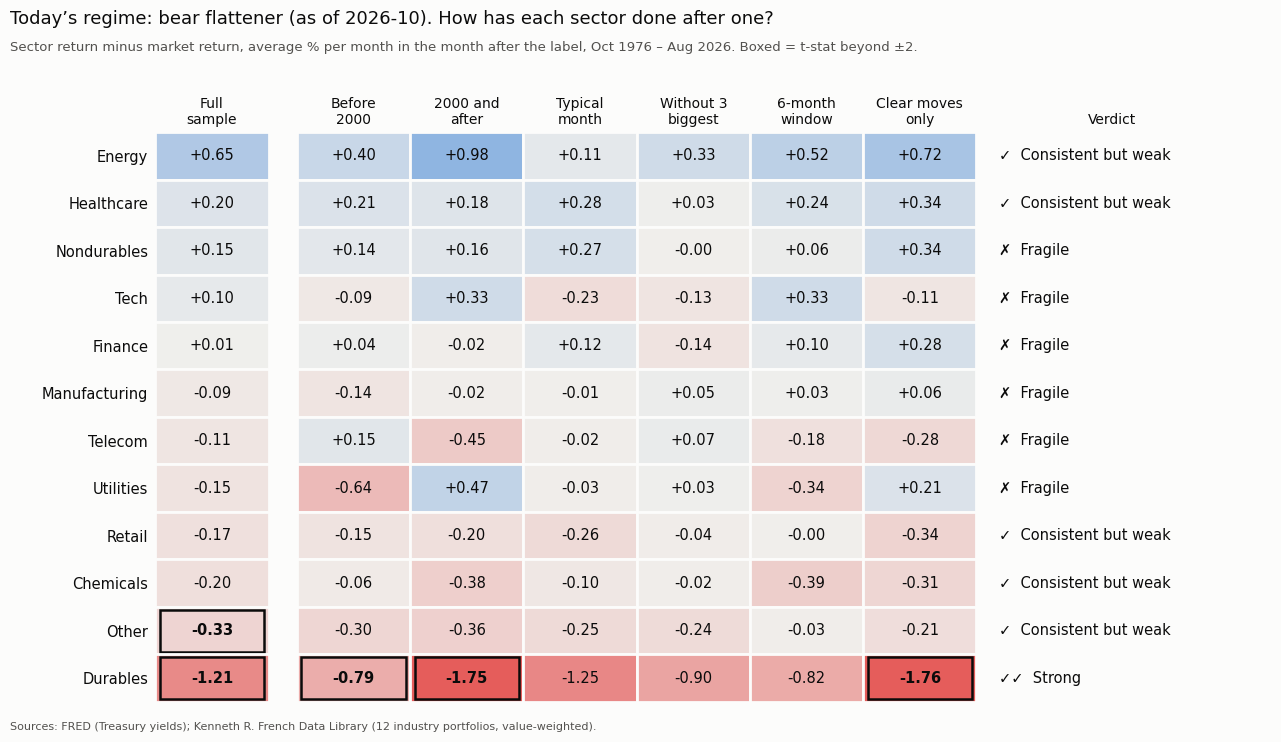

In [6]:
INK, MUTED, BG = "#0b0b0b", "#52514e", "#fcfcfb"
cmap = LinearSegmentedColormap.from_list("lag_to_beat", ["#e34948", "#f0efec", "#2a78d6"])
COLS = ["Full sample"] + CHECKS
TCOL = {"Full sample": "t-stat", **{c: f"t: {c}" for c in VERSIONS}}
vals = ev[COLS]
lim = np.ceil(np.abs(vals.values).max() * 4) / 4
norm = Normalize(-lim, lim)
xs = [0, 1.25, 2.25, 3.25, 4.25, 5.25, 6.25]
MARK = {"Strong": "✓✓  Strong", "Consistent but weak": "✓  Consistent but weak", "Fragile": "✗  Fragile"}

fig, ax = plt.subplots(figsize=(13, 7.4), facecolor=BG)
ax.set_facecolor(BG)
for i, s in enumerate(vals.index):
    for j, col in enumerate(COLS):
        v = vals.loc[s, col]
        ax.add_patch(Rectangle((xs[j], i), 1, 1, facecolor=cmap(norm(v)), edgecolor=BG, linewidth=2))
        strong = col in TCOL and abs(ev.loc[s, TCOL[col]]) >= 2
        if strong:
            ax.add_patch(Rectangle((xs[j] + 0.04, i + 0.06), 0.92, 0.88, fill=False, edgecolor=INK, linewidth=1.8))
        ax.text(xs[j] + 0.5, i + 0.5, f"{v:+.2f}", ha="center", va="center", fontsize=10.5, color=INK,
                fontweight="bold" if strong else "normal")
    ax.text(xs[-1] + 1.2, i + 0.5, MARK[ev.loc[s, "Verdict"]], va="center", fontsize=10.5, color=INK)

ax.set_xlim(-0.02, xs[-1] + 3.6)
ax.set_ylim(len(vals), 0)
ax.xaxis.tick_top()
ax.set_xticks([x + 0.5 for x in xs] + [xs[-1] + 2.2])
ax.set_xticklabels(["Full\nsample", "Before\n2000", "2000 and\nafter", "Typical\nmonth", "Without 3\nbiggest",
                    "6-month\nwindow", "Clear moves\nonly", "Verdict"], color=INK, fontsize=10)
ax.set_yticks([i + 0.5 for i in range(len(vals))])
ax.set_yticklabels(vals.index, color=INK, fontsize=10.5)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
fig.suptitle(f"Today’s regime: {CURRENT.lower()} (as of {lab3.index[-1]}). How has each sector done after one?",
             x=0.02, ha="left", color=INK, fontsize=13, y=0.985)
fig.text(0.02, 0.93, "Sector return minus market return, average % per month in the month after the label, Oct 1976 – Aug 2026. "
         "Boxed = t-stat beyond ±2.", color=MUTED, fontsize=9.5)
fig.text(0.02, 0.012, "Sources: FRED (Treasury yields); Kenneth R. French Data Library (12 industry portfolios, value-weighted).",
         color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.13, right=0.99, top=0.82, bottom=0.05)
fig.savefig(FIGS / "current_regime_scorecard.png", dpi=200, facecolor=BG)
plt.show()

### 7. The shortlist
- **Overweight candidates:** beat the market after this regime **and** held up in the checks (Strong, or Consistent but weak).
- **Underweight candidates:** lagged the market **and** held up.
- Everything else is too uncertain to act on. That is a real answer too: a professional only tilts a portfolio when the evidence is there.

In [7]:
solid = ev["Verdict"] != "Fragile"
over, under = ev[solid & (ev["Full sample"] > 0)], ev[solid & (ev["Full sample"] < 0)]

def show(df, title):
    print(title)
    if df.empty:
        print("   none: no sector held up in this direction\n")
    for s, r in df.iterrows():
        print(f"   {s:13s} {r['Full sample']:+.2f}% per month | t-stat {r['t-stat']:+.1f} | beat the market "
              f"{r['Hit rate %']:.0f}% of months | {r['Verdict']}")
    print()

show(over, f"OVERWEIGHT candidates after a {CURRENT.lower()}:")
show(under.sort_values("Full sample"), f"UNDERWEIGHT candidates after a {CURRENT.lower()}:")
print("Too uncertain to act on:", ", ".join(ev.index[~solid]))

OVERWEIGHT candidates after a bear flattener:
   Energy        +0.65% per month | t-stat +1.5 | beat the market 53% of months | Consistent but weak
   Healthcare    +0.20% per month | t-stat +0.7 | beat the market 53% of months | Consistent but weak

UNDERWEIGHT candidates after a bear flattener:
   Durables      -1.21% per month | t-stat -3.3 | beat the market 34% of months | Strong
   Other         -0.33% per month | t-stat -2.5 | beat the market 44% of months | Consistent but weak
   Chemicals     -0.20% per month | t-stat -1.0 | beat the market 48% of months | Consistent but weak
   Retail        -0.17% per month | t-stat -0.9 | beat the market 47% of months | Consistent but weak

Too uncertain to act on: Nondurables, Tech, Finance, Manufacturing, Telecom, Utilities


### 8. Save the results
This writes `data/latest_regimes.csv` (the last 8 months and their labels) and `data/current_regime_evidence.csv` (every number in the scorecard), plus the chart. Move them into **3 Data** and **4 Charts** on your Mac, and upload them with this notebook to GitHub.

In [8]:
recent.to_csv(DATA / "latest_regimes.csv", index_label="month")
ev.round(2).to_csv(DATA / "current_regime_evidence.csv")
print("Saved", DATA / "latest_regimes.csv", "and", DATA / "current_regime_evidence.csv")
try:                                   # only works inside Google Colab
    from google.colab import files
    for f in [DATA / "latest_regimes.csv", DATA / "current_regime_evidence.csv", FIGS / "current_regime_scorecard.png"]:
        files.download(str(f))
except ImportError:
    print("Not running in Colab: find the files in the data/ and figures/ folders.")

Saved data/latest_regimes.csv and data/current_regime_evidence.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9. Week 7 questions (answer them in the worksheet)
1. **Today’s regime.** What is the latest finished month’s label, and which two 3-month changes produced it? Do the 6-month window and the clear-moves check agree? How many months in a row has it lasted?
2. **The story.** In plain words, what does this regime say the Fed and the economy are doing right now? Check one current news source. Does it fit?
3. **The evidence.** Which sectors look best and worst in this regime, and which of those results held up in the checks?
4. **The call.** Pick one sector to overweight, or explain why you’d stay market weight. Write your thesis in 3 sentences: what, why, and what would change your mind.
5. **The risks.** Name at least two things that could make this call wrong.
6. **The company.** Name 2–3 companies in your sector you could value in Weeks 8–10, and pick one using the checklist in the worksheet.

**Next (Week 8):** build the company’s historical financial model from its annual report (10-K).